In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

from dizx.code import rotated_surface_code
from dizx.realisation import RealisedSED
from dizx.transformations import cut_edges, loop_boundary, prepare_cluster_region
from dizx.zx_diagram import SEDiagram

In [2]:
code = rotated_surface_code(3)
sed = SEDiagram.from_code(code, rounds=2)
central = {v for v in sed.types if v[0] == "data" and v[-1][0] == 1}
S = central | {g for v in central for g in sed.graph.neighbors(v) if g[0] == "gen"}
hsed, S2 = prepare_cluster_region(sed, S)
lsed, S3, rungs = loop_boundary(hsed, S2)
real = RealisedSED.hybrid(lsed, S3, {r: "bell" for r in rungs})
n_loops = len(rungs) // 2
len(cut_edges(hsed, S2)), n_loops, lsed.webs_complete(), lsed.detectors_complete()

(12, 8, True, True)

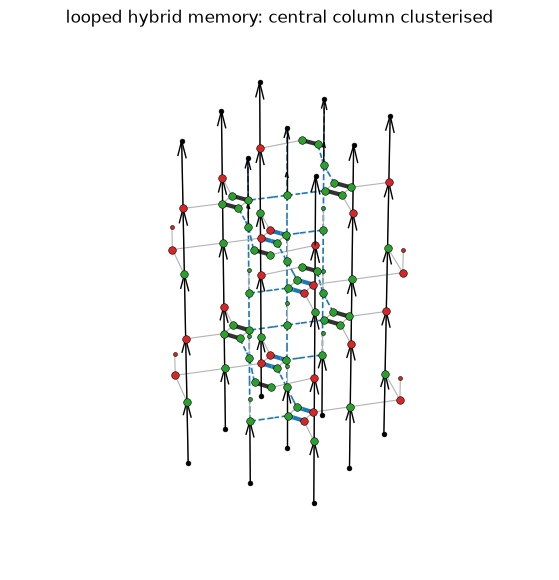

In [3]:
real.draw(title="looped hybrid memory: central column clusterised")
plt.show()

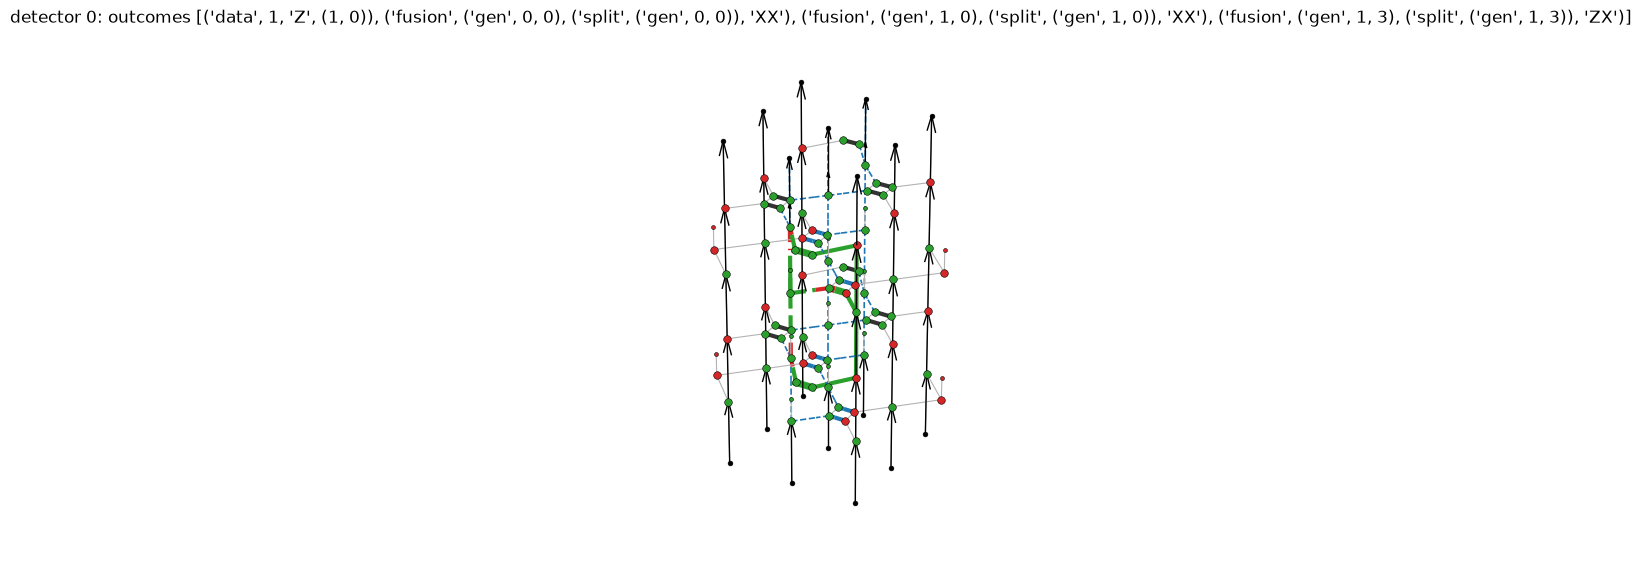

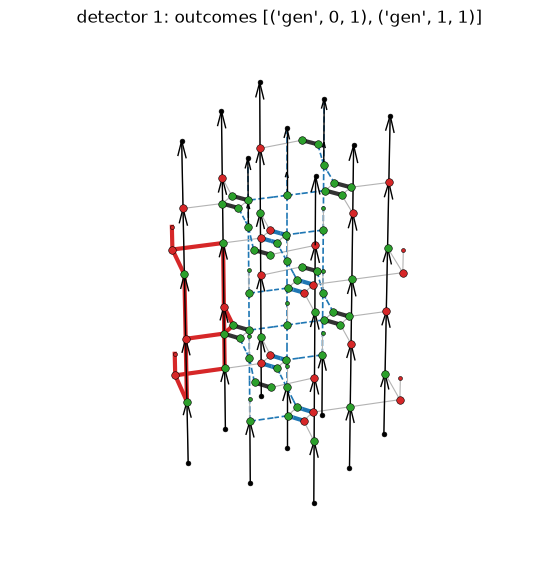

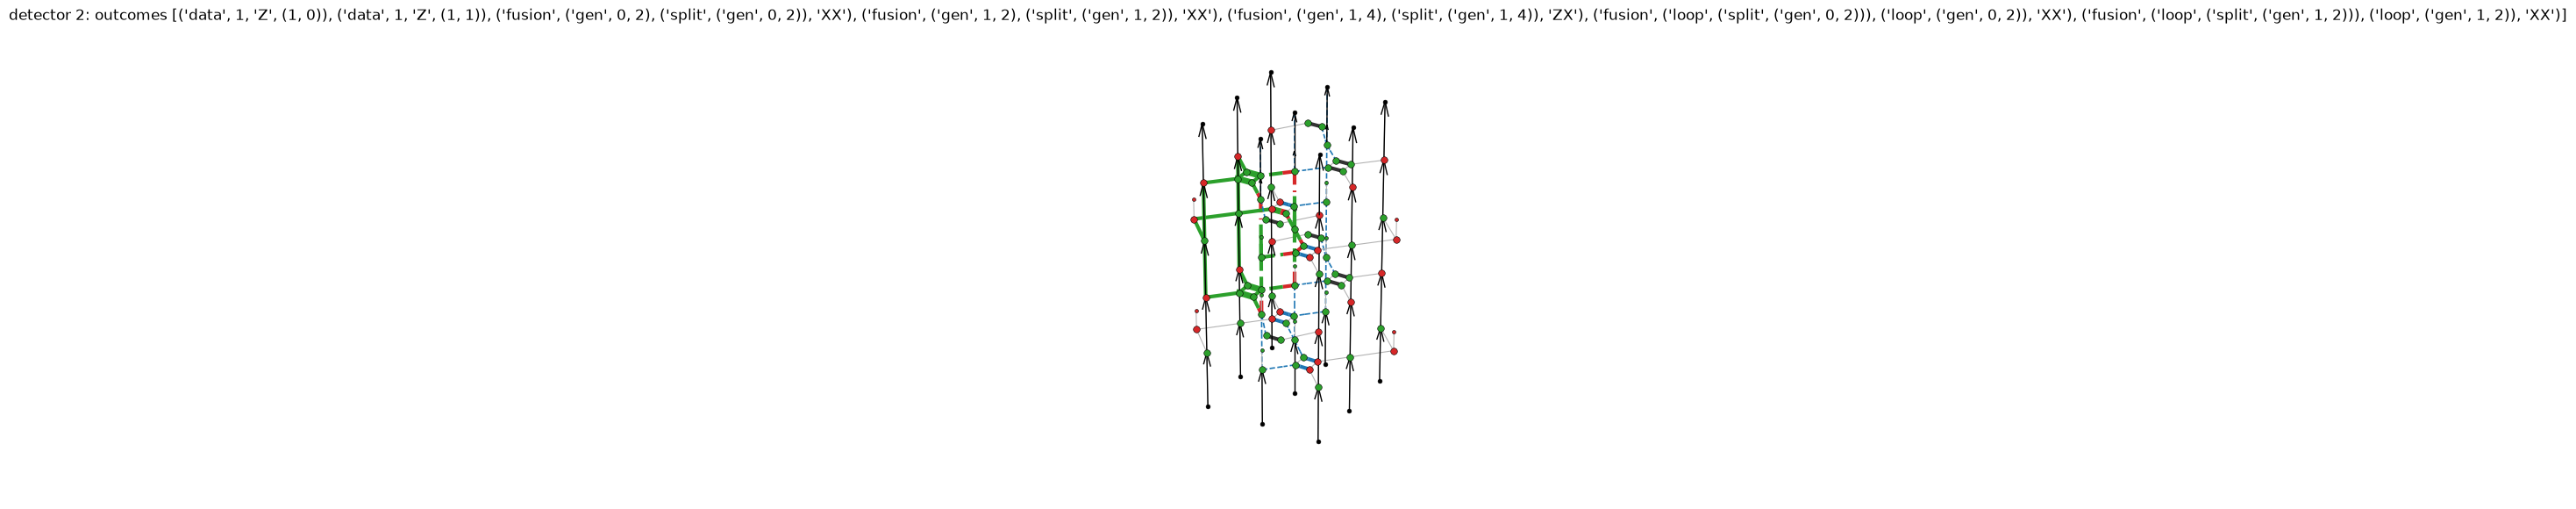

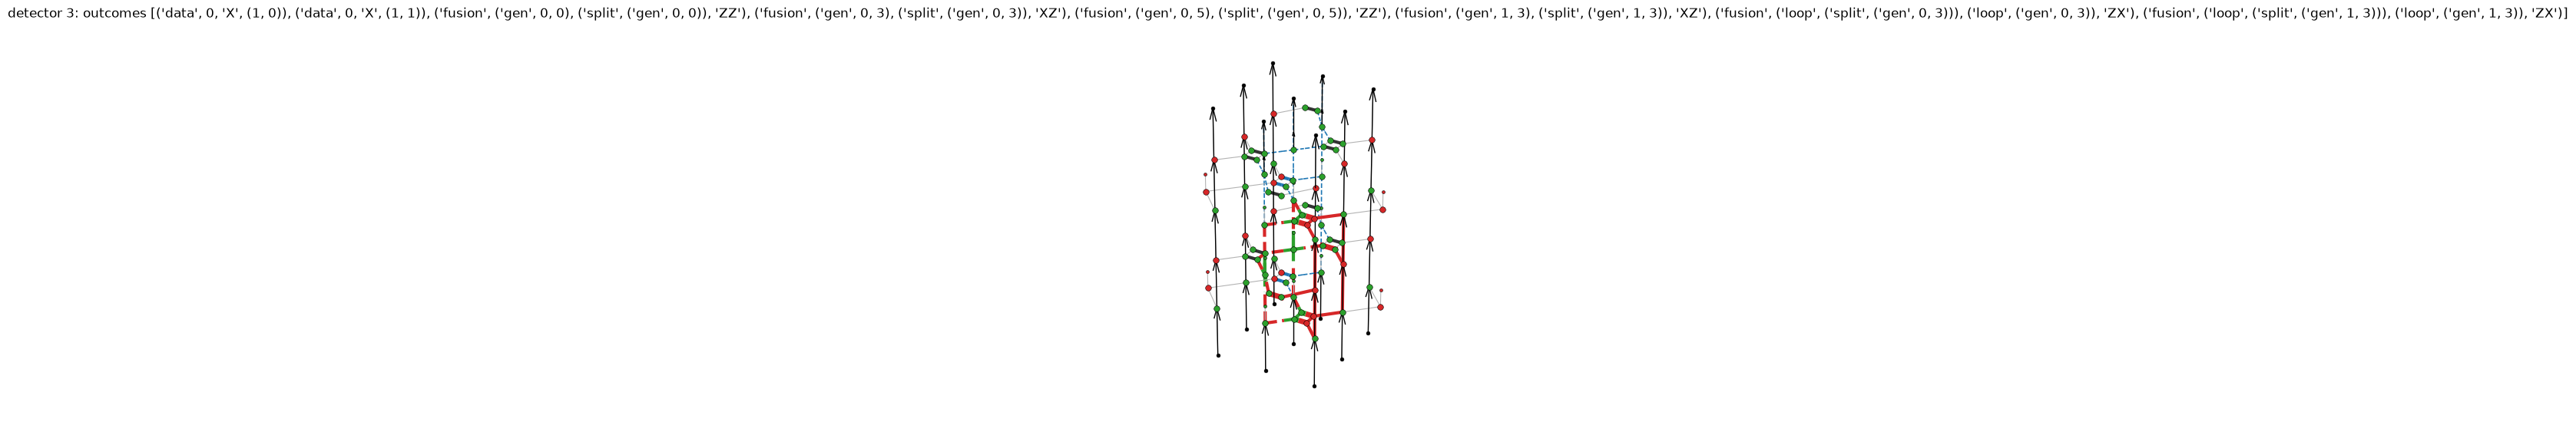

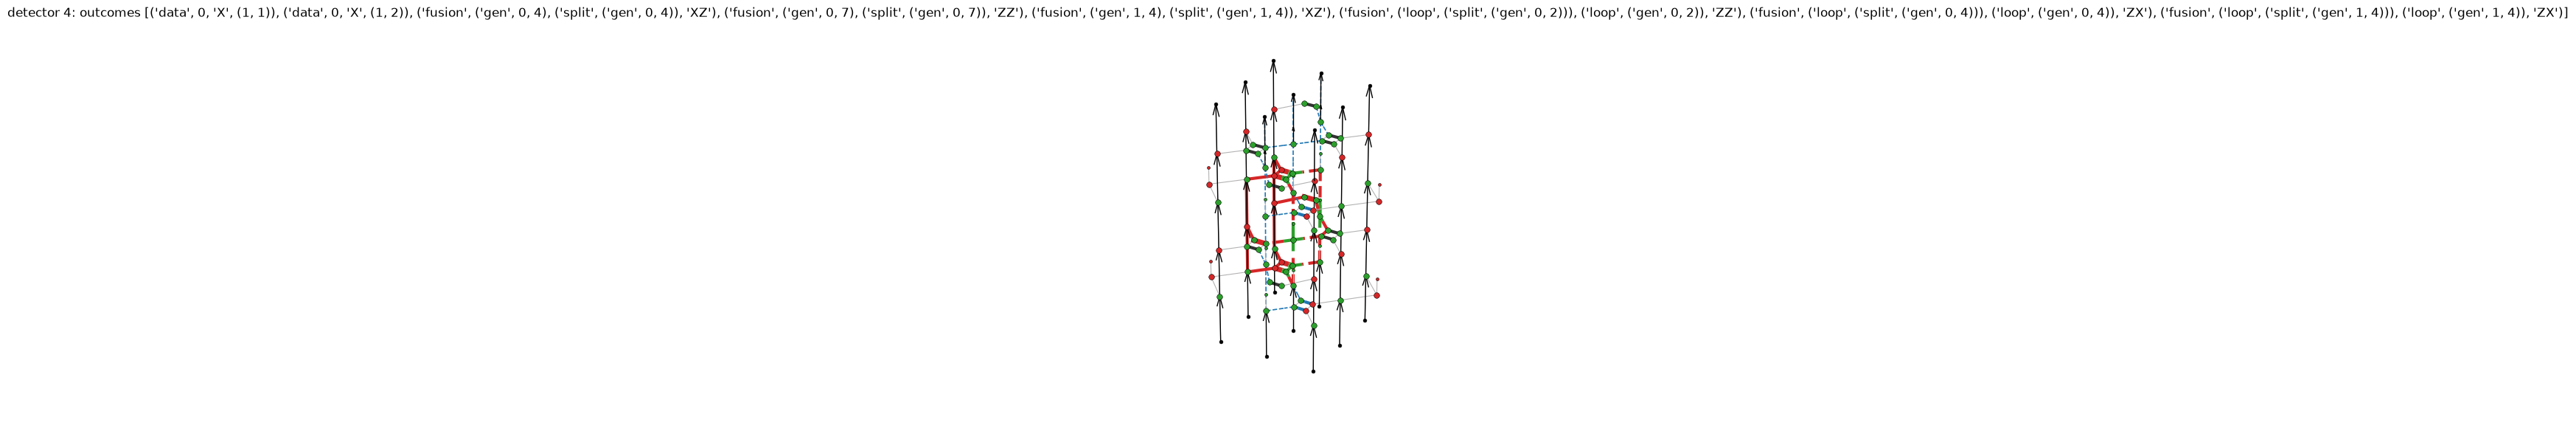

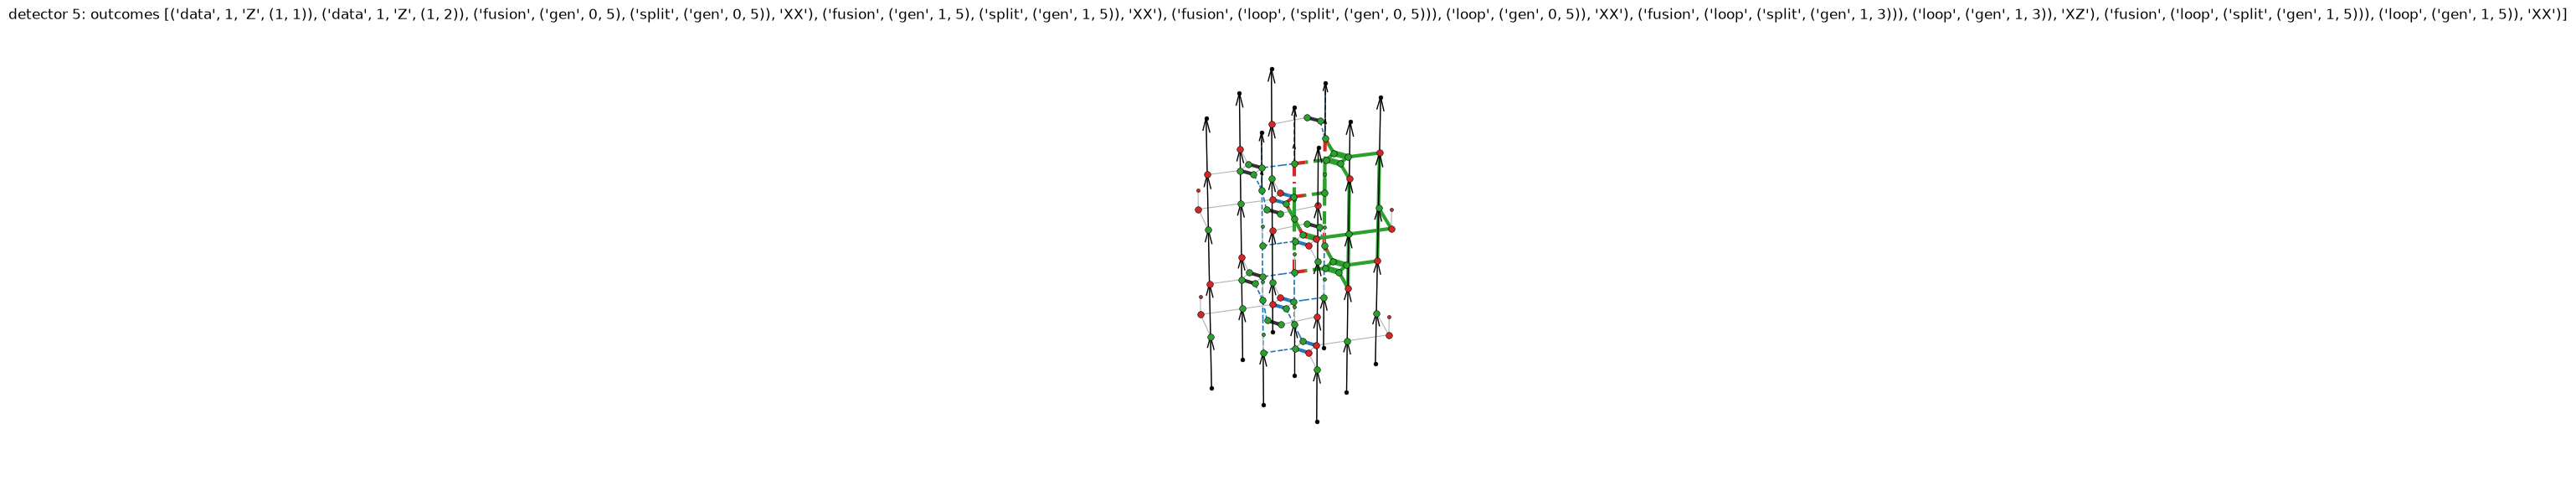

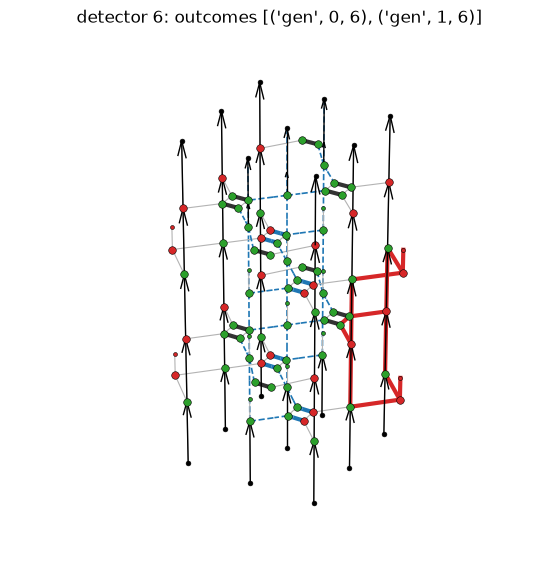

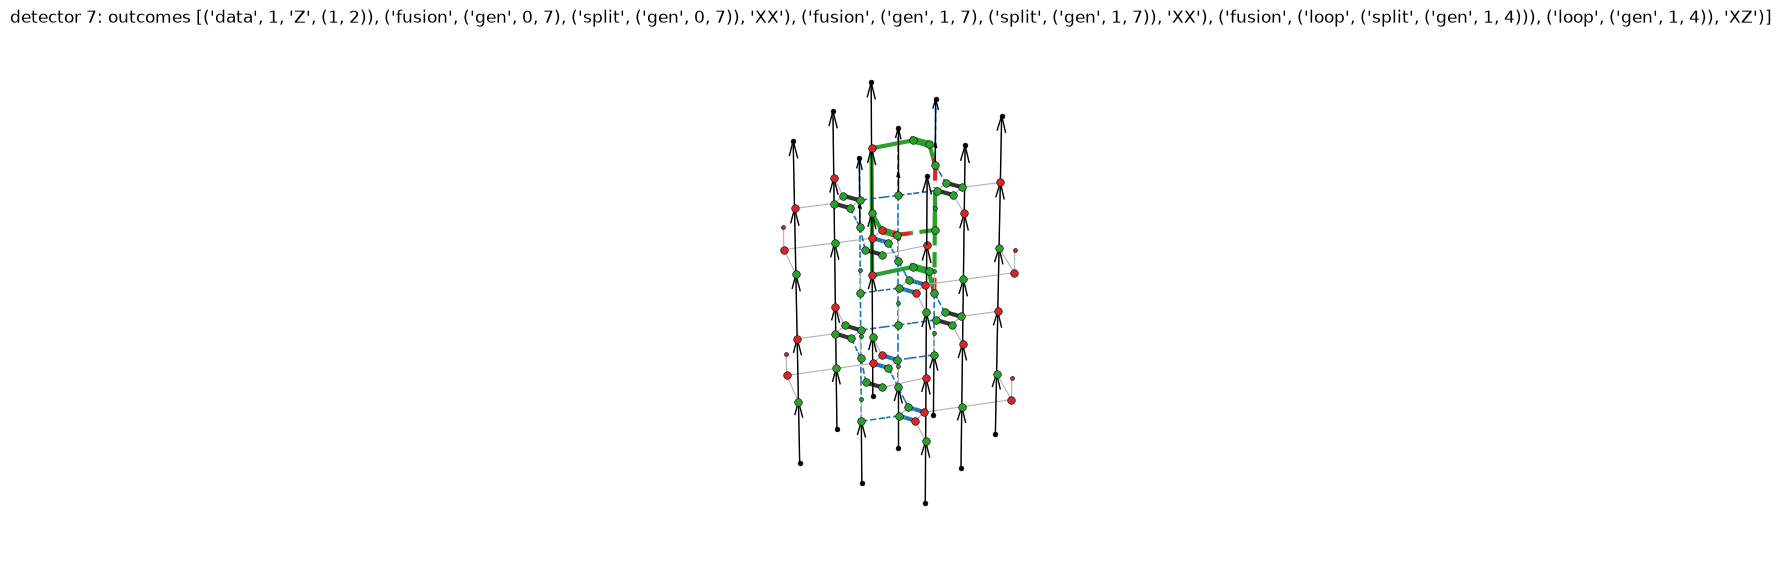

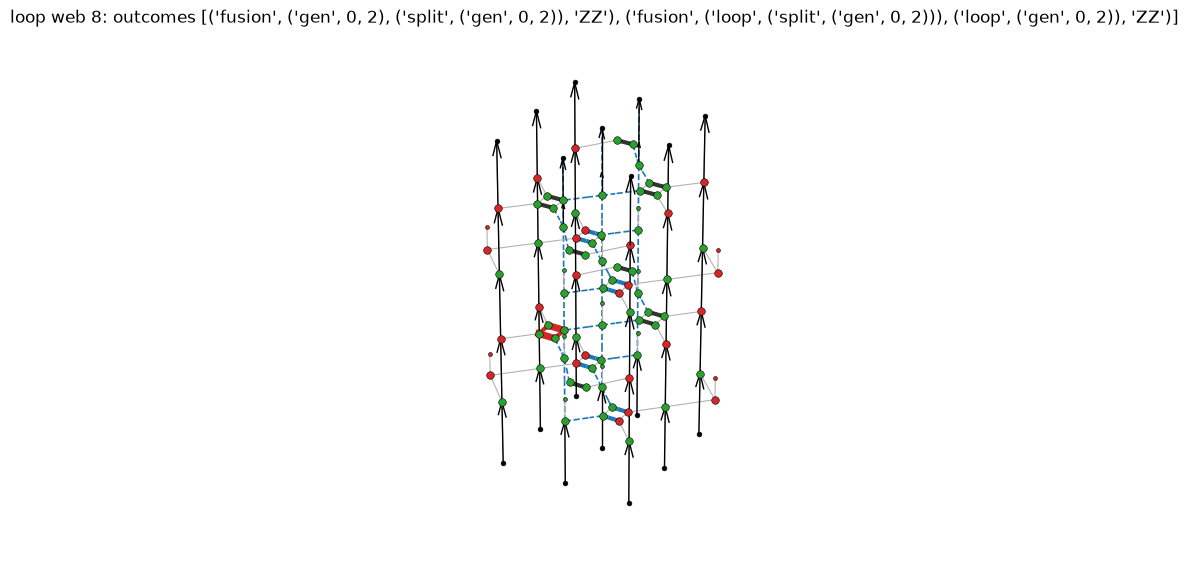

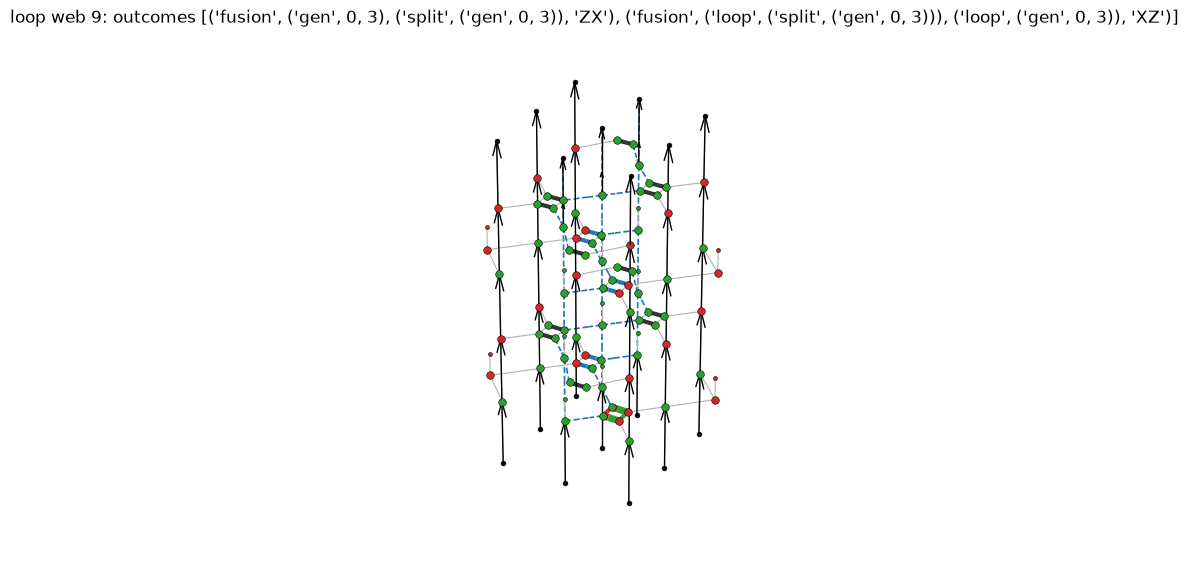

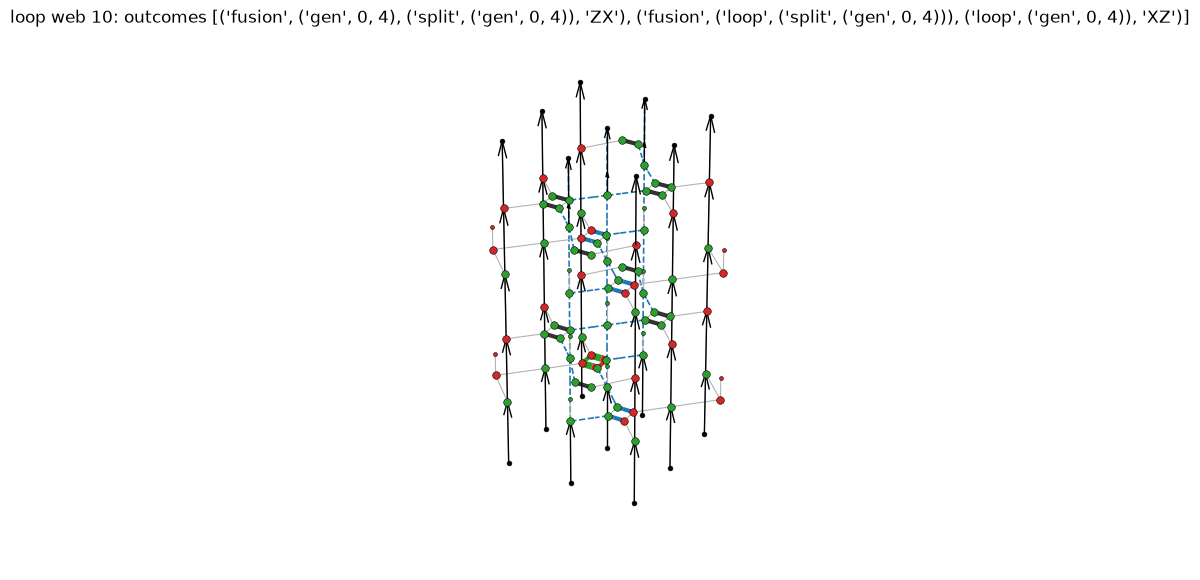

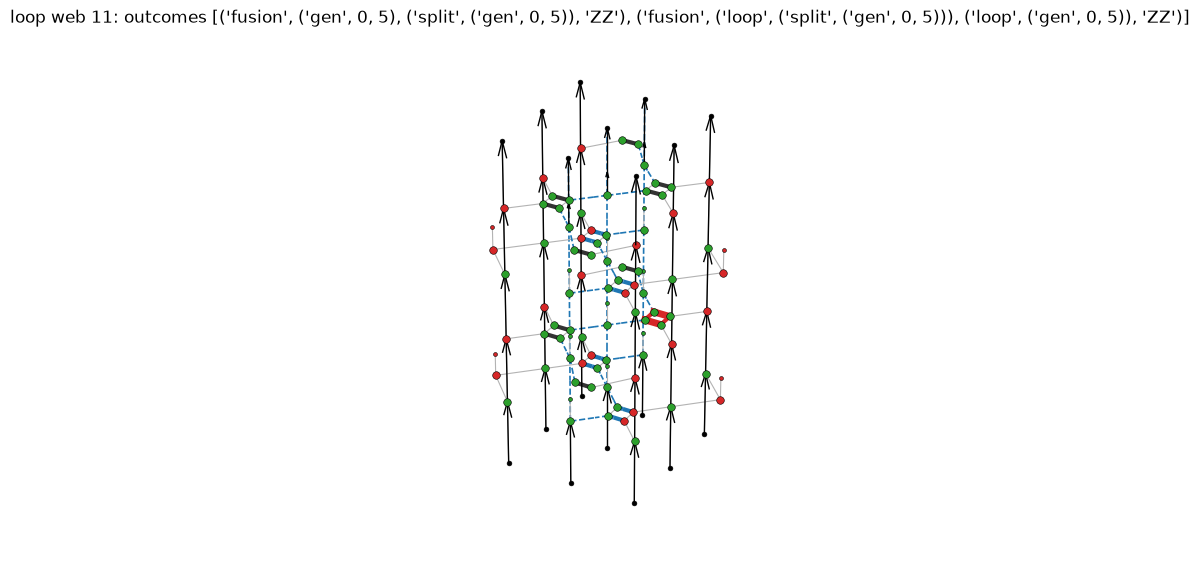

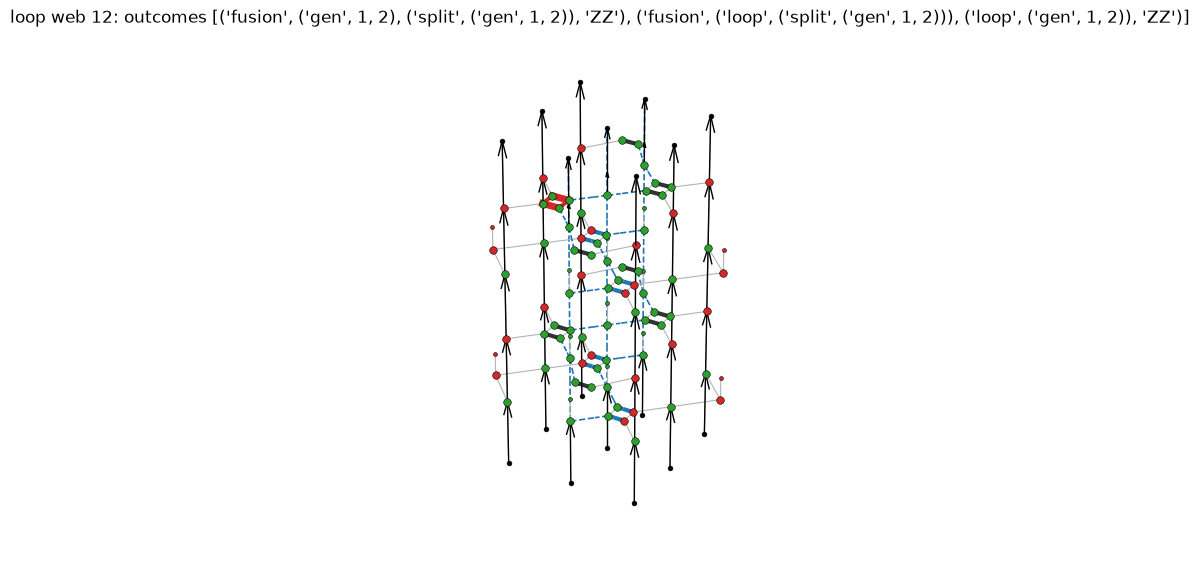

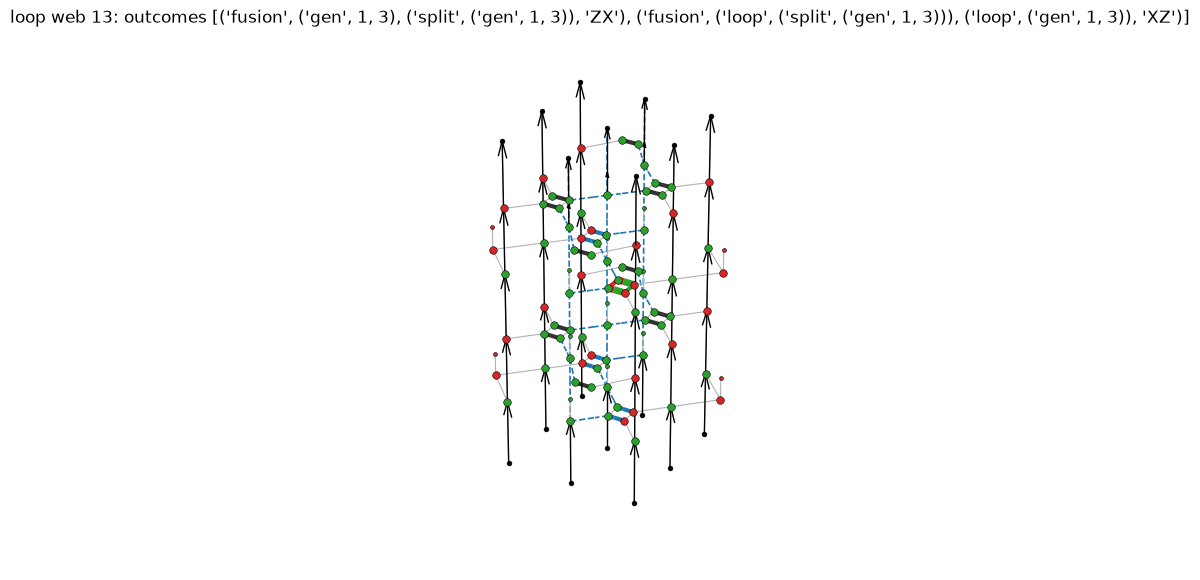

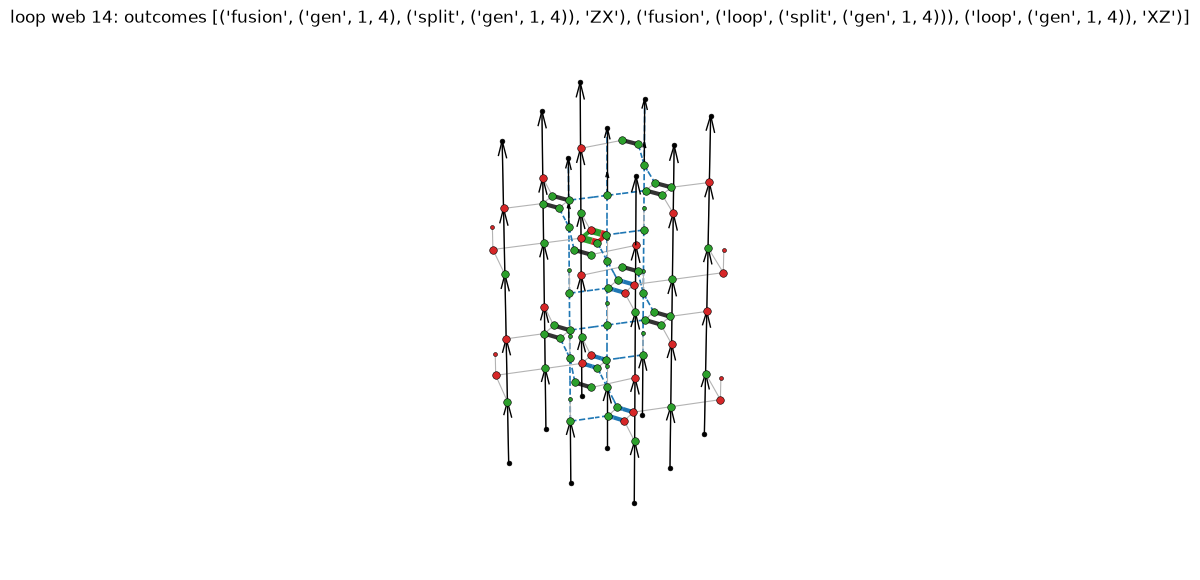

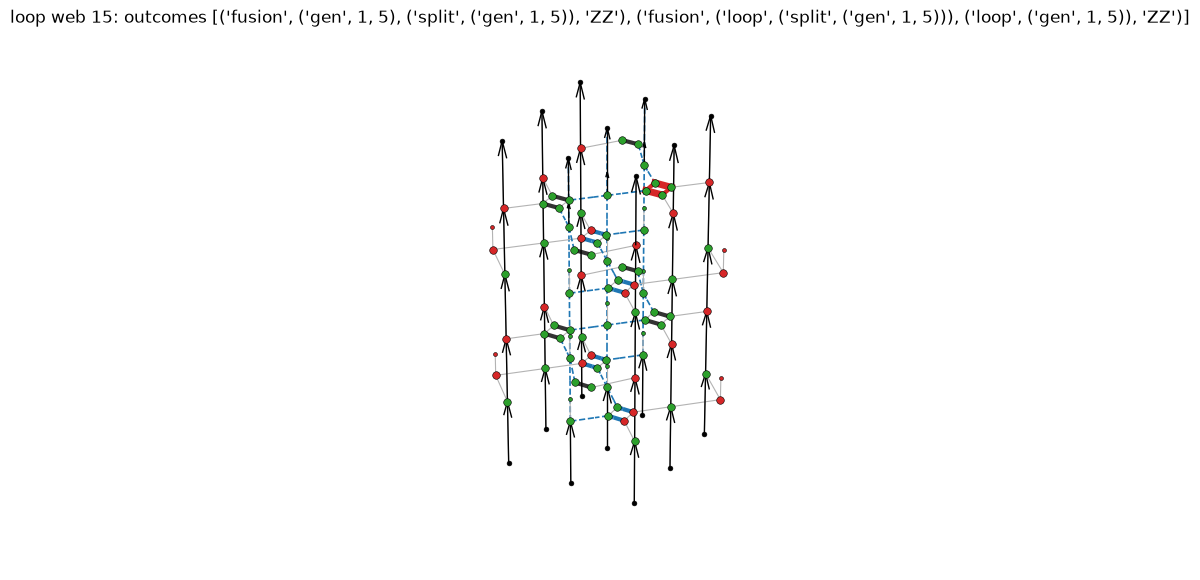

In [4]:
for k, w in enumerate(real.detectors):
    kind = "loop web" if k >= len(real.detectors) - n_loops else "detector"
    real.draw(w, title=f"{kind} {k}: outcomes {sorted(real.record(w), key=repr)}")
    plt.show()

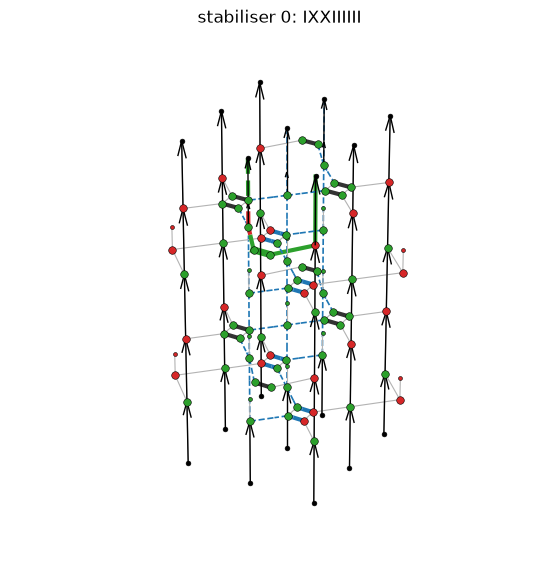

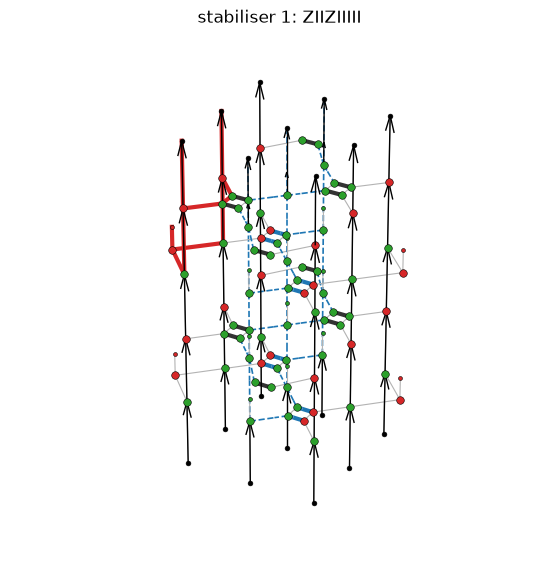

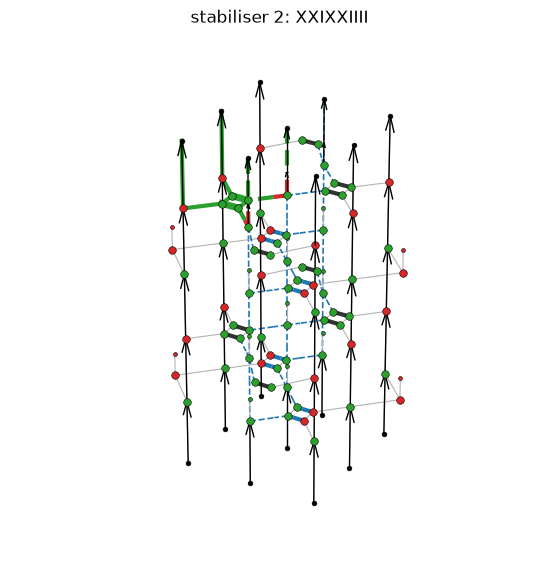

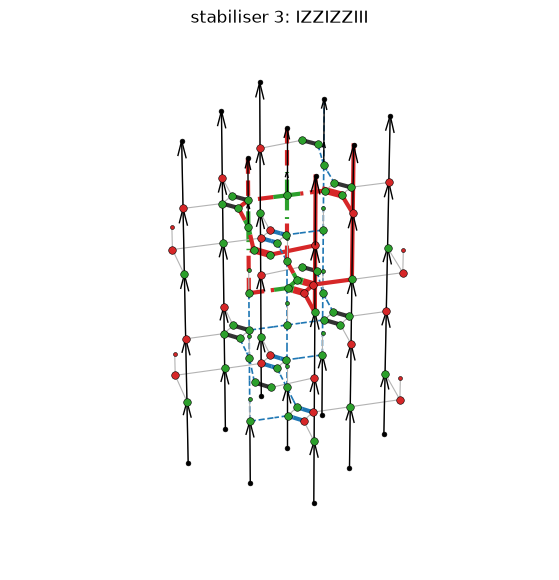

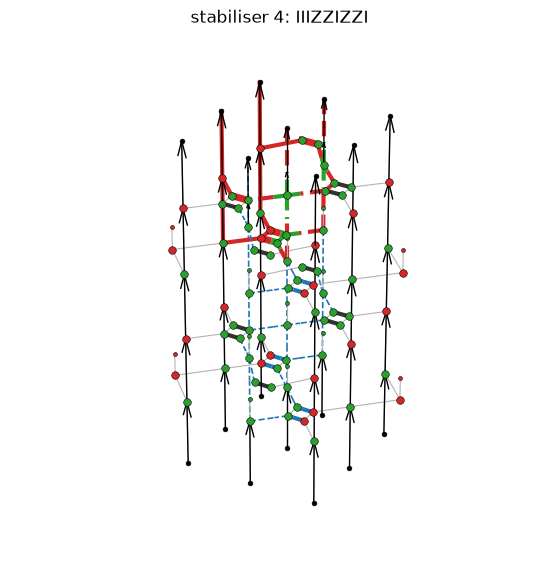

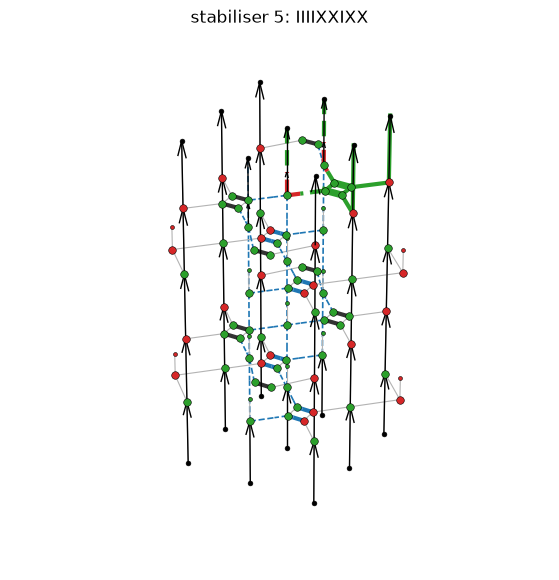

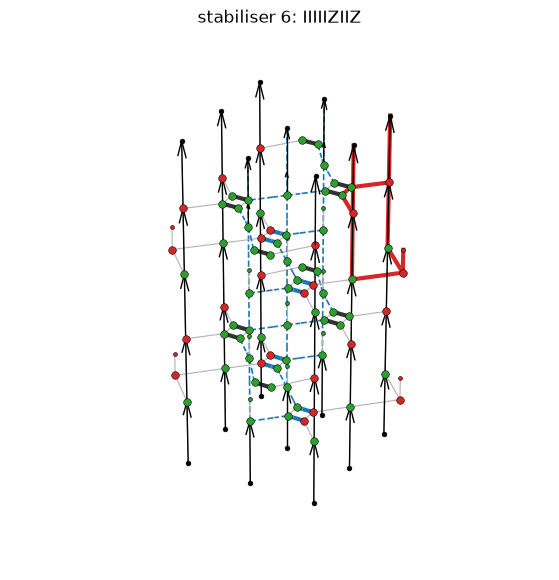

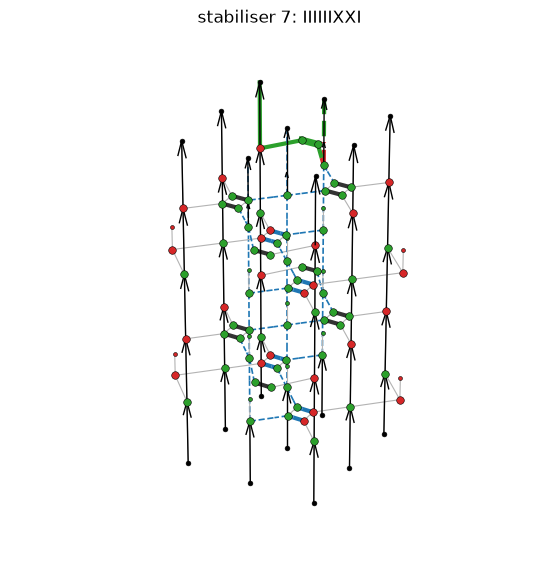

In [5]:
for k, w in enumerate(real.stabilisers):
    real.draw(w, title=f"stabiliser {k}: {w.boundary()[1]}")
    plt.show()

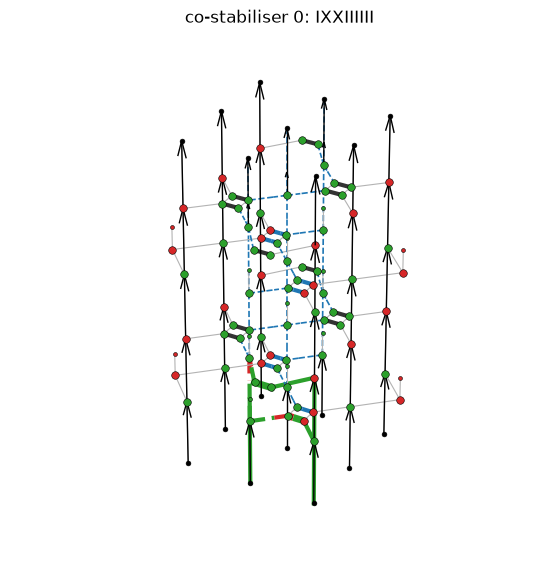

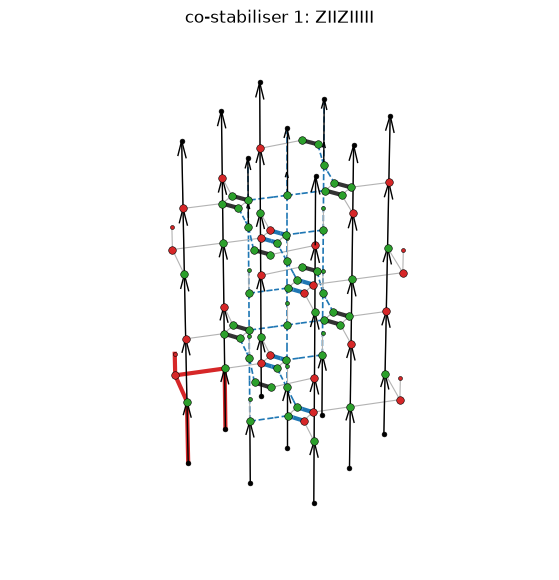

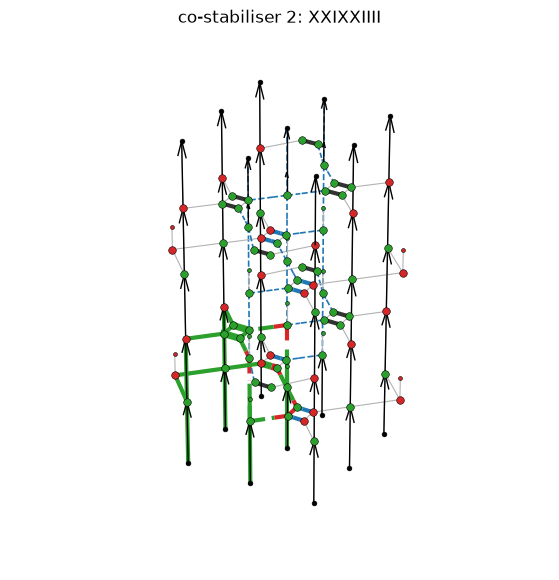

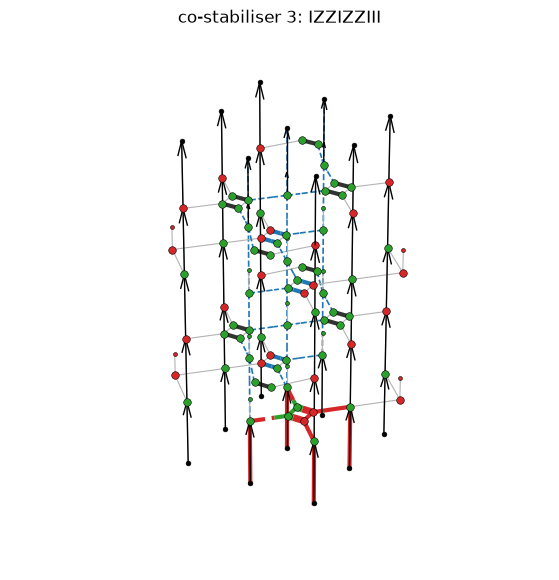

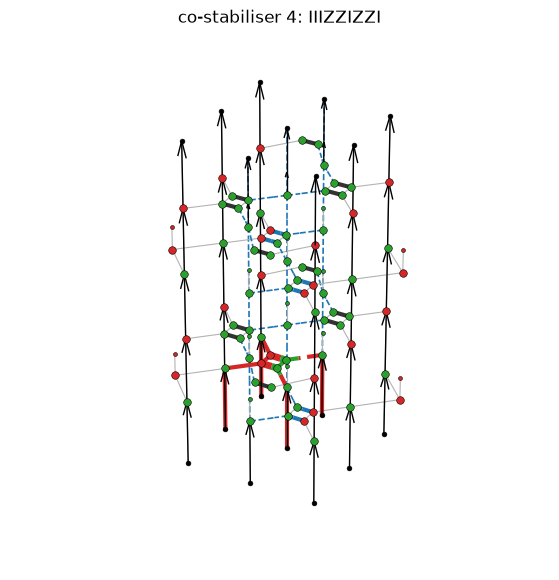

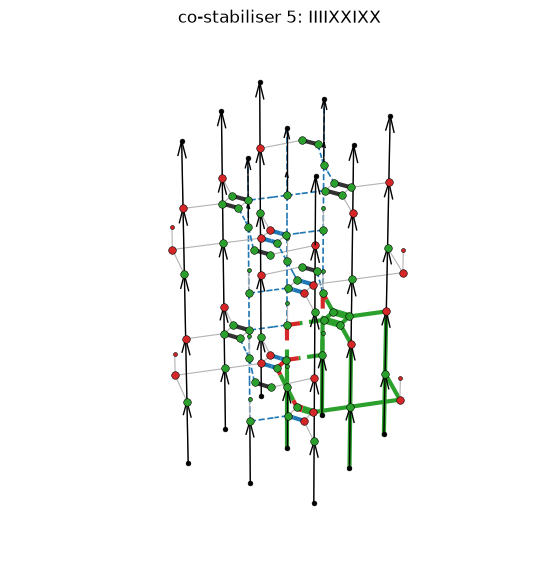

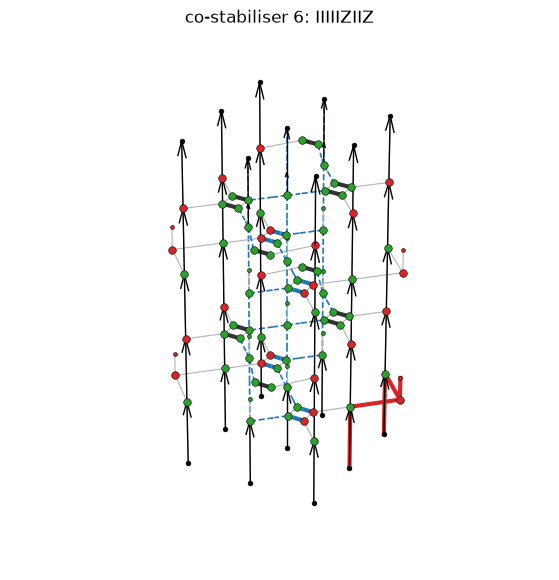

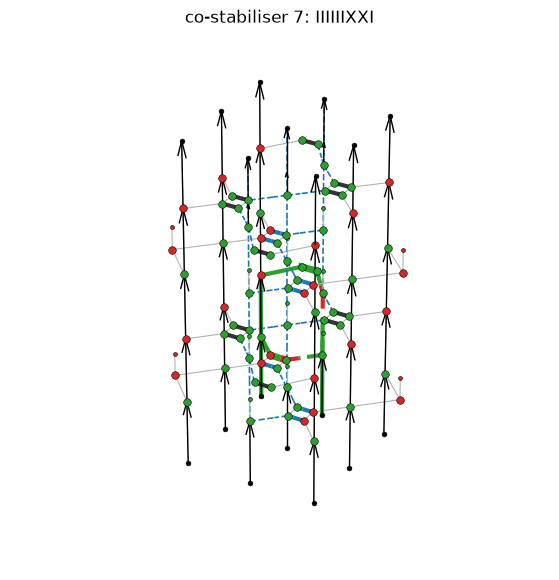

In [6]:
for k, w in enumerate(real.co_stabilisers):
    real.draw(w, title=f"co-stabiliser {k}: {w.boundary()[0]}")
    plt.show()

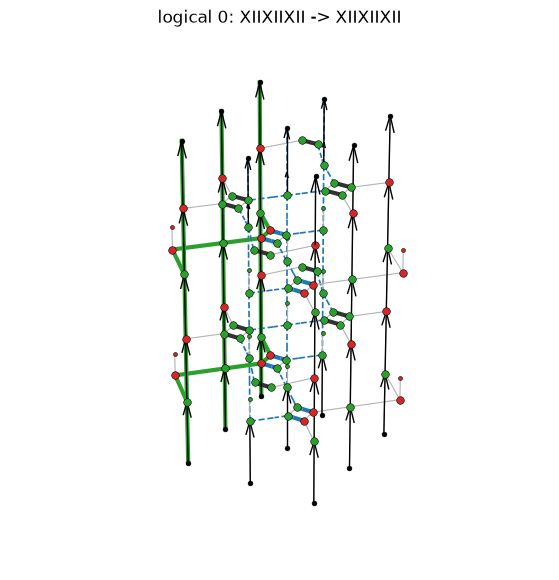

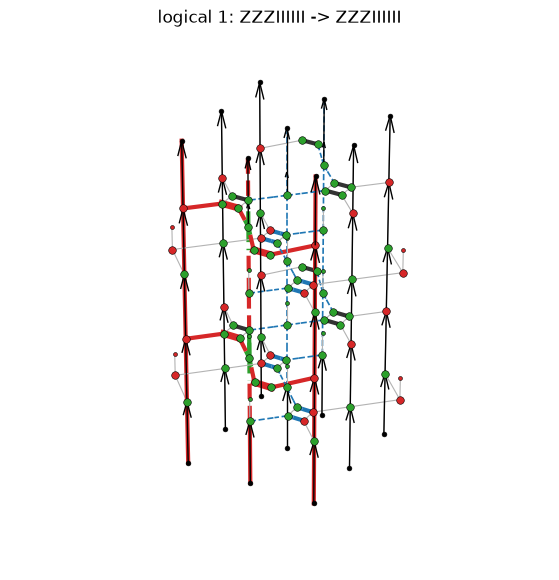

In [7]:
for k, w in enumerate(real.logicals):
    real.draw(w, title=f"logical {k}: {w.boundary()[0]} -> {w.boundary()[1]}")
    plt.show()